# Wafer-map defect classifier on the PYNQ-Z1

Both convolution layers run on the FPGA engine, with zero-skip gating; pooling and the dense layer run on the ARM processor. Every result is compared with `refmodel.py`, the bit-exact integer model the hardware was verified against.

Files needed in this folder: `wafer_accel.bit`, `wafer_accel.hwh`, `wafer_accel.py`, `refmodel.py`, `demo_data.npz`.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import refmodel as rm
from wafer_accel import WaferAccel

acc = WaferAccel("wafer_accel.bit")
print("Overlay loaded, engine found.")

Overlay loaded, engine found.


In [2]:
d = np.load("demo_data.npz")
X, y, names = d["X"], d["y"], [str(n) for n in d["class_names"]]
q = {k: d[k] for k in ("w1", "b1", "sh1", "w2", "b2", "sh2", "s_out2", "fc_w", "fc_b")}
print(f"{len(X)} test maps; classes: {', '.join(names)}")

180 test maps; classes: Center, Donut, Edge-Loc, Edge-Ring, Loc, Near-full, Random, Scratch, none


## One wafer map

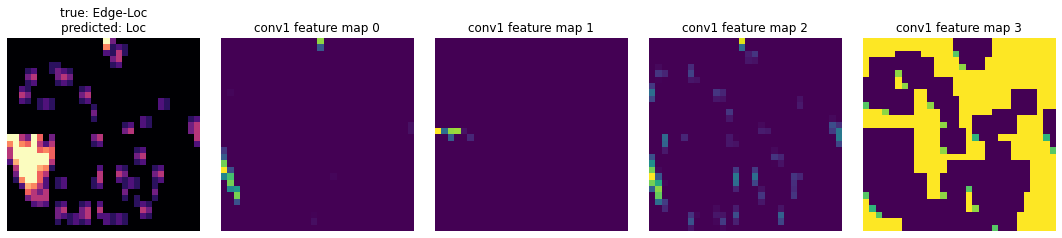

Hardware matches the reference model bit for bit. 79.2% of multiply-accumulates skipped. 335 ms for this map.


In [3]:
i = 0
logits, info = acc.run_network(X[i], q)
ref_logits, ref = rm.run_network(X[i][None], q, return_intermediate=True)

assert np.array_equal(info["conv1"], ref["conv1_out"][0]), "conv1 differs from the reference model"
assert np.array_equal(info["conv2"], ref["conv2_out"][0]), "conv2 differs from the reference model"
pred = int(np.argmax(logits))
skip = sum(info["skipped"]) / sum(info["taps"])

fig, ax = plt.subplots(1, 5, figsize=(15, 3.2))
ax[0].imshow(X[i], cmap="magma"); ax[0].set_title(f"true: {names[y[i]]}\npredicted: {names[pred]}")
for j in range(4):
    ax[j + 1].imshow(info["conv1"][j], cmap="viridis"); ax[j + 1].set_title(f"conv1 feature map {j}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print(f"Hardware matches the reference model bit for bit. {skip:.1%} of multiply-accumulates skipped. "
      f"{info['seconds'] * 1000:.0f} ms for this map.")

## The whole demo set

In [4]:
preds, agree, skipped, taps, secs = [], 0, 0, 0, 0.0
for i in range(len(X)):
    logits, info = acc.run_network(X[i], q)
    ref_logits = rm.run_network(X[i][None], q)
    preds.append(int(np.argmax(logits)))
    agree += int(np.argmax(logits) == np.argmax(ref_logits[0]))
    skipped += sum(info["skipped"]); taps += sum(info["taps"]); secs += info["seconds"]
preds = np.array(preds)

print(f"Maps: {len(X)}   accuracy: {(preds == y).mean():.1%}   same prediction as the reference model: {agree}/{len(X)}")
print(f"Taps skipped: {skipped / taps:.1%}   average time per map: {secs / len(X) * 1000:.0f} ms")
print()
print(f"{'Class':<11}{'Maps':>6}{'Correct':>9}")
for k, n in enumerate(names):
    m = y == k
    print(f"{n:<11}{int(m.sum()):>6}{int((preds[m] == k).sum()):>9}")

Maps: 180   accuracy: 75.6%   same prediction as the reference model: 180/180
Taps skipped: 68.1%   average time per map: 302 ms

Class        Maps  Correct
Center         20       17
Donut          20       20
Edge-Loc       20       11
Edge-Ring      20       17
Loc            20        6
Near-full      20       19
Random         20       18
Scratch        20        8
none           20       20


## Gating on and off

Gating never changes the results, only how much the multipliers switch. The PYNQ-Z1 has no on-board power monitor for the FPGA, so the energy effect is estimated from simulation instead (see the project spec). This cell confirms the outputs are identical either way.

In [5]:
outs = {}
for gate in (True, False):
    acc.gate = gate
    _, info = acc.run_network(X[0], q)
    outs[gate] = (info["conv1"], info["conv2"])
acc.gate = True
same = all(np.array_equal(a, b) for a, b in zip(outs[True], outs[False]))
print("Identical results with gating on and off:", same)

Identical results with gating on and off: True
